# Microscopy Image Denoising — Results Analysis

## Overview

This notebook presents a comparative analysis of three deep learning approaches for microscopy image denoising:

- **E3 – Standard U-Net**
- **E4 – U-Net with Edge Loss**
- **E5 – DnCNN**

The experiments are evaluated using quantitative image quality metrics and qualitative visual comparisons.

## Objectives

1. Compare the denoising performance of different architectures.
2. Analyse PSNR and SSIM scores.
3. Visualize denoising results on identical test images.
4. Examine reconstruction errors and structural preservation.
5. Identify the strengths and limitations of each approach.

In [3]:
import os

base_path = "/content/drive/MyDrive/Microscopy-Denoising"

for root, dirs, files in os.walk(base_path):
    dirs[:] = [d for d in dirs if d not in ["plots", "predictions"]]

    for file in files:
        if file.endswith((".pth", ".pt", ".csv")):
            print(os.path.join(root, file))

In [4]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
import os

base_path = "/content/drive/MyDrive/Microscopy-Denoising"

for root, dirs, files in os.walk(base_path):
    dirs[:] = [d for d in dirs if d not in ["plots", "predictions"]]

    for file in files:
        if file.endswith((".pth", ".pt", ".csv")):
            print(os.path.join(root, file))

/content/drive/MyDrive/Microscopy-Denoising/standard_unet_results.csv
/content/drive/MyDrive/Microscopy-Denoising/experiment_comparison_E3_E4.csv
/content/drive/MyDrive/Microscopy-Denoising/experiment_comparison_E3_E4_E6.csv
/content/drive/MyDrive/Microscopy-Denoising/experiment_comparison_E3_E4_E5.csv
/content/drive/MyDrive/Microscopy-Denoising/dncnn_results.csv
/content/drive/MyDrive/Microscopy-Denoising/checkpoints/unet_best.pth
/content/drive/MyDrive/Microscopy-Denoising/checkpoints/unet_latest.pth
/content/drive/MyDrive/Microscopy-Denoising/checkpoints/unet_edge_best.pth
/content/drive/MyDrive/Microscopy-Denoising/checkpoints/dncnn_best.pth


In [6]:
import torch
import pandas as pd
import os

base_path = "/content/drive/MyDrive/Microscopy-Denoising"
checkpoint_dir = os.path.join(base_path, "checkpoints")

checkpoints = {
    "E3 - Standard U-Net": "unet_best.pth",
    "E4 - U-Net + Edge Loss": "unet_edge_best.pth",
    "E5 - DnCNN": "dncnn_best.pth"
}

for name, filename in checkpoints.items():
    path = os.path.join(checkpoint_dir, filename)
    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    print("\n", name)
    print("Checkpoint keys:", checkpoint.keys())

    if "epoch" in checkpoint:
        print("Best epoch:", checkpoint["epoch"])

    if "val_loss" in checkpoint:
        print("Validation loss:", checkpoint["val_loss"])

print("\n--- STANDARD U-NET RESULTS ---")
display(pd.read_csv(os.path.join(base_path, "standard_unet_results.csv")))

print("\n--- FINAL COMPARISON ---")
display(pd.read_csv(os.path.join(
    base_path, "experiment_comparison_E3_E4_E5.csv"
)))


 E3 - Standard U-Net
Checkpoint keys: odict_keys(['encoder1.conv.conv.0.weight', 'encoder1.conv.conv.0.bias', 'encoder1.conv.conv.2.weight', 'encoder1.conv.conv.2.bias', 'encoder2.conv.conv.0.weight', 'encoder2.conv.conv.0.bias', 'encoder2.conv.conv.2.weight', 'encoder2.conv.conv.2.bias', 'encoder3.conv.conv.0.weight', 'encoder3.conv.conv.0.bias', 'encoder3.conv.conv.2.weight', 'encoder3.conv.conv.2.bias', 'encoder4.conv.conv.0.weight', 'encoder4.conv.conv.0.bias', 'encoder4.conv.conv.2.weight', 'encoder4.conv.conv.2.bias', 'bottleneck.conv.conv.0.weight', 'bottleneck.conv.conv.0.bias', 'bottleneck.conv.conv.2.weight', 'bottleneck.conv.conv.2.bias', 'decoder4.up.weight', 'decoder4.up.bias', 'decoder4.conv.conv.0.weight', 'decoder4.conv.conv.0.bias', 'decoder4.conv.conv.2.weight', 'decoder4.conv.conv.2.bias', 'decoder3.up.weight', 'decoder3.up.bias', 'decoder3.conv.conv.0.weight', 'decoder3.conv.conv.0.bias', 'decoder3.conv.conv.2.weight', 'decoder3.conv.conv.2.bias', 'decoder2.up.weig

,Metric,Value
0,PSNR,33.564546
1,SSIM,0.948840



--- FINAL COMPARISON ---


,Experiment,PSNR,SSIM
0,E3 - Standard U-Net,33.564500,0.948840
1,E4 - U-Net + Edge Loss,33.180900,0.944860
2,E5 - DnCNN,32.497644,0.924147


In [7]:
import pandas as pd
import os

test_csv_url = "https://raw.githubusercontent.com/suyash-jaiswal-7/Microscopy-Denoising/main/outputs/splits/test.csv"

test_csv = pd.read_csv(test_csv_url)

print("Test images:", len(test_csv))
print("\nSample filenames:")
display(test_csv.head())

Test images: 369

Sample filenames:


,filename
0,3225.tif
1,3196.tif
2,2612.tif
3,2518.tif
4,2942.tif


In [8]:
import os

noisy_dir = "/content/microscopy_data/small_images/noisy"
gt_dir = "/content/microscopy_data/small_images/gt"

missing_noisy = [
    f for f in test_csv["filename"]
    if not os.path.exists(os.path.join(noisy_dir, f))
]

missing_gt = [
    f for f in test_csv["filename"]
    if not os.path.exists(os.path.join(gt_dir, f))
]

print("Missing noisy images:", len(missing_noisy))
print("Missing ground-truth images:", len(missing_gt))

print("All test image pairs available:",
      len(missing_noisy) == 0 and len(missing_gt) == 0)

Missing noisy images: 369
Missing ground-truth images: 369
All test image pairs available: False


In [9]:
import os

print("Folders inside /content:")
print(os.listdir("/content"))

print("\nChecking expected dataset paths:")

for path in [
    "/content/microscopy_data",
    "/content/microscopy_data/small_images",
    "/content/microscopy_data/small_images/noisy",
    "/content/microscopy_data/small_images/gt"
]:
    print(path, "->", os.path.exists(path))

Folders inside /content:
['.config', 'drive', 'sample_data']

Checking expected dataset paths:
/content/microscopy_data -> False
/content/microscopy_data/small_images -> False
/content/microscopy_data/small_images/noisy -> False
/content/microscopy_data/small_images/gt -> False


In [10]:
import os
import urllib.request
import hashlib
import zipfile

url = "https://zenodo.org/records/15624741/files/Archive.zip?download=1"
zip_path = "/content/Archive.zip"

urllib.request.urlretrieve(url, zip_path)

# Verify dataset checksum
md5 = hashlib.md5()

with open(zip_path, "rb") as f:
    for chunk in iter(lambda: f.read(1024 * 1024), b""):
        md5.update(chunk)

print("MD5:", md5.hexdigest())
print("Expected: 6a268178418294bb86705fb925a6c532")
print("Checksum verified:", md5.hexdigest() == "6a268178418294bb86705fb925a6c532")

MD5: 6a268178418294bb86705fb925a6c532
Expected: 6a268178418294bb86705fb925a6c532
Checksum verified: True


In [11]:
import zipfile
import os

extract_path = "/content/microscopy_data"

with zipfile.ZipFile("/content/Archive.zip", "r") as zip_ref:
    zip_ref.extractall(extract_path)

noisy_dir = os.path.join(extract_path, "small_images", "noisy")
gt_dir = os.path.join(extract_path, "small_images", "gt")

print("Noisy images:", len(os.listdir(noisy_dir)))
print("Ground truth images:", len(os.listdir(gt_dir)))

Noisy images: 2457
Ground truth images: 2457


In [12]:
missing_noisy = [
    f for f in test_csv["filename"]
    if not os.path.isfile(os.path.join(noisy_dir, f))
]

missing_gt = [
    f for f in test_csv["filename"]
    if not os.path.isfile(os.path.join(gt_dir, f))
]

print("Missing noisy:", len(missing_noisy))
print("Missing GT:", len(missing_gt))
print("All pairs available:", len(missing_noisy) == 0 and len(missing_gt) == 0)

Missing noisy: 0
Missing GT: 0
All pairs available: True


In [13]:
import os
from google.colab import drive

drive.mount('/content/drive')

checkpoint_dir = "/content/drive/MyDrive/Microscopy-Denoising/checkpoints"

checkpoints = {
    "E3 - Standard U-Net": "unet_best.pth",
    "E4 - U-Net + Edge Loss": "unet_edge_best.pth",
    "E5 - DnCNN": "dncnn_best.pth"
}

for experiment, filename in checkpoints.items():
    path = os.path.join(checkpoint_dir, filename)

    print(experiment)
    print("Exists:", os.path.exists(path))

    if os.path.exists(path):
        print("Size:", round(os.path.getsize(path) / (1024 * 1024), 2), "MB")

    print("-" * 40)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
E3 - Standard U-Net
Exists: True
Size: 118.39 MB
----------------------------------------
E4 - U-Net + Edge Loss
Exists: True
Size: 118.39 MB
----------------------------------------
E5 - DnCNN
Exists: True
Size: 6.47 MB
----------------------------------------


In [15]:

import os
import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

BASE = "/content/drive/MyDrive/Microscopy-Denoising"
CKPT = os.path.join(BASE, "checkpoints")


# ==========================================
# 1. U-NET ARCHITECTURE (E3 AND E4)
# ==========================================

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


class Encoder(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = DoubleConv(in_channels, out_channels)

    def forward(self, x):
        return self.conv(x)


class Decoder(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.up = nn.ConvTranspose2d(
            in_channels, out_channels, kernel_size=2, stride=2
        )
        self.conv = DoubleConv(out_channels * 2, out_channels)

    def forward(self, x, skip):
        x = self.up(x)
        x = torch.cat([x, skip], dim=1)
        return self.conv(x)


class OutputLayer(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=1)

    def forward(self, x):
        return self.conv(x)


class UNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.pool = nn.MaxPool2d(2)

        self.encoder1 = Encoder(1, 64)
        self.encoder2 = Encoder(64, 128)
        self.encoder3 = Encoder(128, 256)
        self.encoder4 = Encoder(256, 512)

        # Correct checkpoint-compatible bottleneck
        self.bottleneck = Encoder(512, 1024)

        self.decoder4 = Decoder(1024, 512)
        self.decoder3 = Decoder(512, 256)
        self.decoder2 = Decoder(256, 128)
        self.decoder1 = Decoder(128, 64)

        self.output_layer = OutputLayer(64, 1)

    def forward(self, x):
        e1 = self.encoder1(x)
        e2 = self.encoder2(self.pool(e1))
        e3 = self.encoder3(self.pool(e2))
        e4 = self.encoder4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.decoder4(b, e4)
        d3 = self.decoder3(d4, e3)
        d2 = self.decoder2(d3, e2)
        d1 = self.decoder1(d2, e1)

        return self.output_layer(d1)


# ==========================================
# 2. DnCNN ARCHITECTURE (E5)
# ==========================================

class DnCNN(nn.Module):
    def __init__(self, channels=64, num_layers=17):
        super().__init__()

        layers = [
            nn.Conv2d(1, channels, 3, padding=1),
            nn.ReLU(inplace=True)
        ]

        for _ in range(num_layers - 2):
            layers.extend([
                nn.Conv2d(channels, channels, 3, padding=1),
                nn.BatchNorm2d(channels),
                nn.ReLU(inplace=True)
            ])

        layers.append(nn.Conv2d(channels, 1, 3, padding=1))

        self.dncnn = nn.Sequential(*layers)

    def forward(self, x):
        return self.dncnn(x)


# ==========================================
# 3. LOAD ALL THREE CHECKPOINTS
# ==========================================

e3_model = UNet().to(device)
e4_model = UNet().to(device)
e5_model = DnCNN().to(device)

e3_state = torch.load(
    os.path.join(CKPT, "unet_best.pth"),
    map_location=device,
    weights_only=True
)

e4_state = torch.load(
    os.path.join(CKPT, "unet_edge_best.pth"),
    map_location=device,
    weights_only=True
)

e5_checkpoint = torch.load(
    os.path.join(CKPT, "dncnn_best.pth"),
    map_location=device,
    weights_only=False
)

e3_model.load_state_dict(e3_state)
e4_model.load_state_dict(e4_state)
e5_model.load_state_dict(e5_checkpoint["model_state_dict"])

for model in [e3_model, e4_model, e5_model]:
    model.eval()


# ==========================================
# 4. VERIFY LOADING
# ==========================================

print("ALL MODELS LOADED SUCCESSFULLY!")
print("-" * 45)

print("Device:", device)

print("E3 - Standard U-Net parameters:",
      sum(p.numel() for p in e3_model.parameters()))

print("E4 - U-Net + Edge Loss parameters:",
      sum(p.numel() for p in e4_model.parameters()))

print("E5 - DnCNN parameters:",
      sum(p.numel() for p in e5_model.parameters()))

print("E5 best checkpoint epoch:", e5_checkpoint["epoch"])
print("E5 validation loss:", e5_checkpoint["val_loss"])


ALL MODELS LOADED SUCCESSFULLY!
---------------------------------------------
Device: cuda
E3 - Standard U-Net parameters: 31030593
E4 - U-Net + Edge Loss parameters: 31030593
E5 - DnCNN parameters: 557057
E5 best checkpoint epoch: 9
E5 validation loss: 0.0006218272287279015


In [16]:

import numpy as np
import pandas as pd
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from tqdm.auto import tqdm

NOISY_SCALE = 78.0
GT_SCALE = 2252.0

noisy_dir = "/content/microscopy_data/small_images/noisy"
gt_dir = "/content/microscopy_data/small_images/gt"

results = []

# Store predictions for later visual comparison
predictions = {
    "E3 - Standard U-Net": [],
    "E4 - U-Net + Edge Loss": [],
    "E5 - DnCNN": []
}

for filename in tqdm(test_csv["filename"], desc="Evaluating test images"):

    noisy_img = np.array(
        Image.open(os.path.join(noisy_dir, filename)),
        dtype=np.float32
    ) / NOISY_SCALE

    gt_img = np.array(
        Image.open(os.path.join(gt_dir, filename)),
        dtype=np.float32
    ) / GT_SCALE

    noisy_tensor = torch.from_numpy(noisy_img).unsqueeze(0).unsqueeze(0).to(device)

    with torch.no_grad():
        e3_pred = e3_model(noisy_tensor)
        e4_pred = e4_model(noisy_tensor)

        e5_noise = e5_model(noisy_tensor)
        e5_pred = noisy_tensor - e5_noise

    model_outputs = {
        "E3 - Standard U-Net": e3_pred,
        "E4 - U-Net + Edge Loss": e4_pred,
        "E5 - DnCNN": e5_pred
    }

    for model_name, output in model_outputs.items():

        pred_img = output[0, 0].cpu().numpy()

        psnr = peak_signal_noise_ratio(
            gt_img, pred_img, data_range=1.0
        )

        ssim = structural_similarity(
            gt_img, pred_img, data_range=1.0
        )

        results.append({
            "Filename": filename,
            "Experiment": model_name,
            "PSNR": psnr,
            "SSIM": ssim
        })

        predictions[model_name].append(pred_img)

results_df = pd.DataFrame(results)

print("Evaluation completed!")
print("Total predictions:", len(results_df))
print("Test images:", len(test_csv))
print("Models evaluated:", results_df["Experiment"].nunique())


Evaluating test images:   0%|          | 0/369 [00:00<?, ?it/s]

Evaluation completed!
Total predictions: 1107
Test images: 369
Models evaluated: 3


In [17]:

# Average metrics for each experiment

comparison_df = (
    results_df
    .groupby("Experiment")[["PSNR", "SSIM"]]
    .mean()
    .reset_index()
)

comparison_df = comparison_df.sort_values(
    by="PSNR", ascending=False
).reset_index(drop=True)

print("FINAL TEST SET COMPARISON")
display(comparison_df.round(5))


FINAL TEST SET COMPARISON


,Experiment,PSNR,SSIM
0,E3 - Standard U-Net,33.56455,0.94884
1,E4 - U-Net + Edge Loss,33.18091,0.94486
2,E5 - DnCNN,32.49764,0.92415


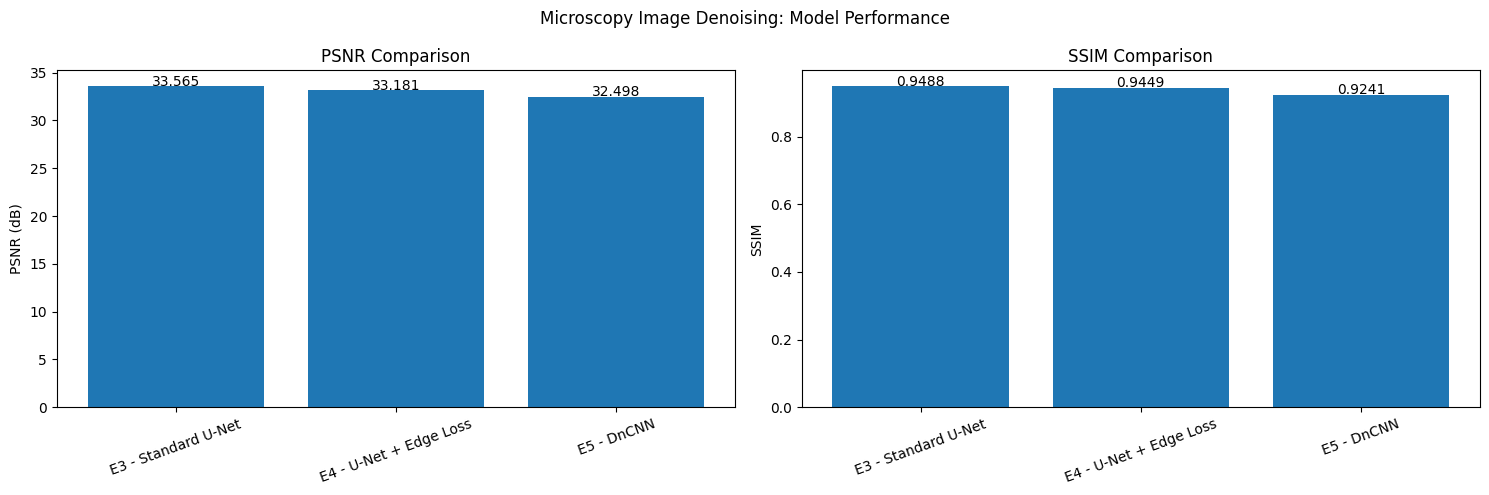

In [18]:

import matplotlib.pyplot as plt
import numpy as np

experiments = comparison_df["Experiment"]
psnr_values = comparison_df["PSNR"]
ssim_values = comparison_df["SSIM"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# PSNR comparison
axes[0].bar(experiments, psnr_values)
axes[0].set_title("PSNR Comparison")
axes[0].set_ylabel("PSNR (dB)")
axes[0].tick_params(axis="x", rotation=20)

for i, value in enumerate(psnr_values):
    axes[0].text(i, value + 0.03, f"{value:.3f}", ha="center")

# SSIM comparison
axes[1].bar(experiments, ssim_values)
axes[1].set_title("SSIM Comparison")
axes[1].set_ylabel("SSIM")
axes[1].tick_params(axis="x", rotation=20)

for i, value in enumerate(ssim_values):
    axes[1].text(i, value + 0.001, f"{value:.4f}", ha="center")

plt.suptitle("Microscopy Image Denoising: Model Performance")
plt.tight_layout()
plt.show()


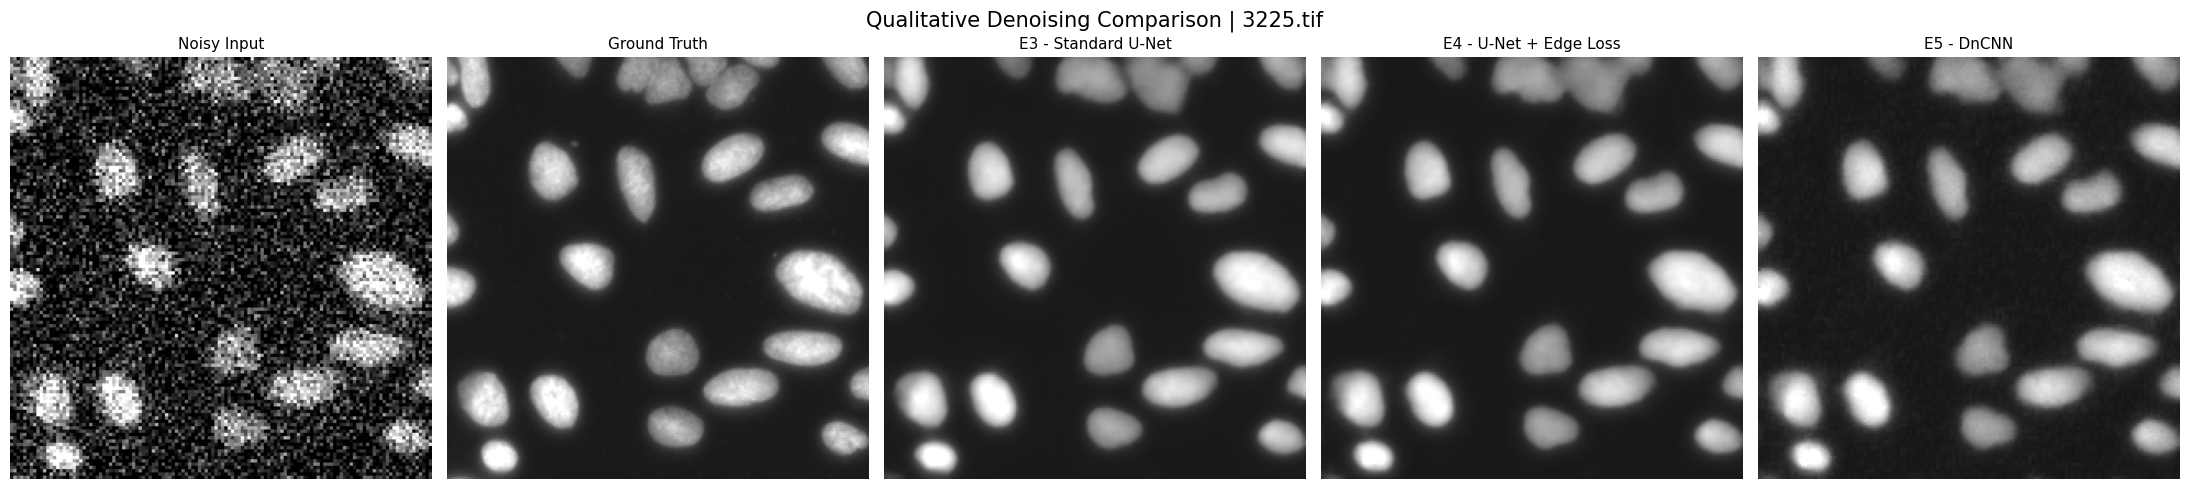

In [19]:

import matplotlib.pyplot as plt
import numpy as np

# Select one test image
idx = 0
filename = test_csv.iloc[idx]["filename"]

# Load original images
noisy_img = np.array(
    Image.open(os.path.join(noisy_dir, filename)),
    dtype=np.float32
) / NOISY_SCALE

gt_img = np.array(
    Image.open(os.path.join(gt_dir, filename)),
    dtype=np.float32
) / GT_SCALE

# Retrieve predictions in the same test-set order
e3_img = predictions["E3 - Standard U-Net"][idx]
e4_img = predictions["E4 - U-Net + Edge Loss"][idx]
e5_img = predictions["E5 - DnCNN"][idx]

images = [
    noisy_img,
    gt_img,
    e3_img,
    e4_img,
    e5_img
]

titles = [
    "Noisy Input",
    "Ground Truth",
    "E3 - Standard U-Net",
    "E4 - U-Net + Edge Loss",
    "E5 - DnCNN"
]

# Shared intensity range for fair visual comparison
all_pixels = np.concatenate([img.ravel() for img in images])
vmin, vmax = np.percentile(all_pixels, [1, 99])

fig, axes = plt.subplots(1, 5, figsize=(22, 5))

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img, cmap="gray", vmin=vmin, vmax=vmax)
    ax.set_title(title, fontsize=11)
    ax.axis("off")

plt.suptitle(
    f"Qualitative Denoising Comparison | {filename}",
    fontsize=15
)

plt.tight_layout()
plt.show()


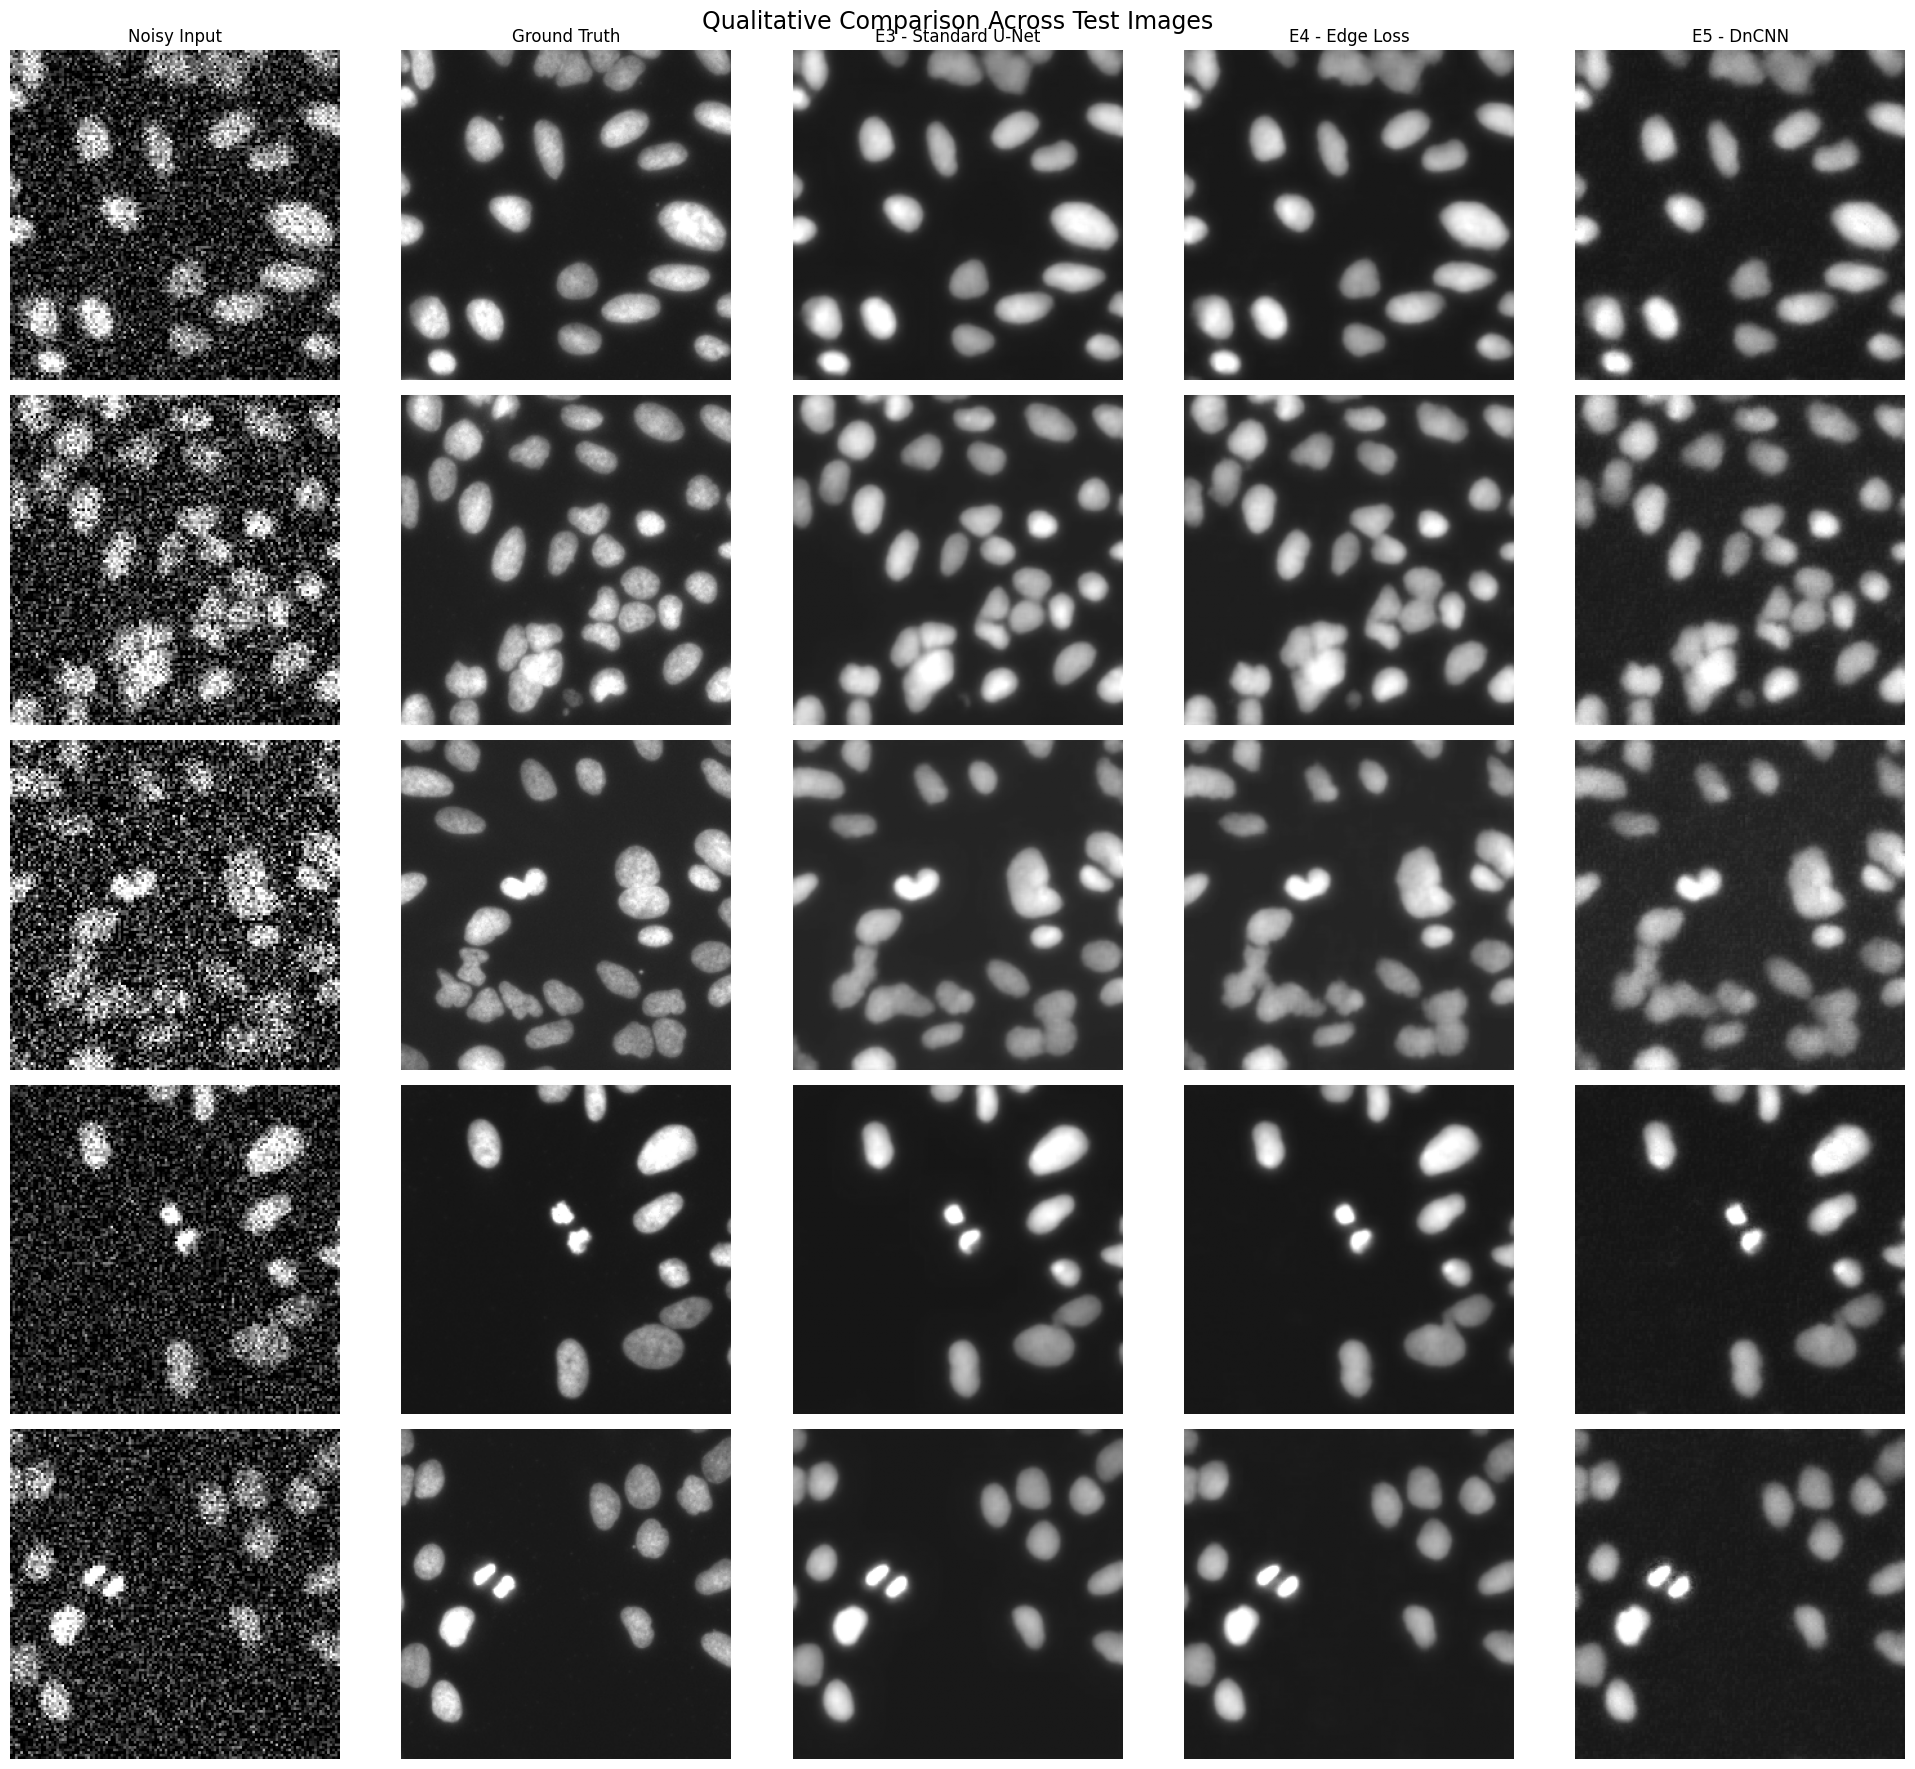

In [20]:
import matplotlib.pyplot as plt
import numpy as np
import os
from PIL import Image

sample_indices = [0, 10, 25, 50, 100]

fig, axes = plt.subplots(5, 5, figsize=(20, 18))

titles = [
    "Noisy Input",
    "Ground Truth",
    "E3 - Standard U-Net",
    "E4 - Edge Loss",
    "E5 - DnCNN"
]

for row, idx in enumerate(sample_indices):

    filename = test_csv.iloc[idx]["filename"]

    noisy = np.array(
        Image.open(os.path.join(noisy_dir, filename)),
        dtype=np.float32
    ) / NOISY_SCALE

    gt = np.array(
        Image.open(os.path.join(gt_dir, filename)),
        dtype=np.float32
    ) / GT_SCALE

    images = [
        noisy,
        gt,
        predictions["E3 - Standard U-Net"][idx],
        predictions["E4 - U-Net + Edge Loss"][idx],
        predictions["E5 - DnCNN"][idx]
    ]

    all_pixels = np.concatenate([img.ravel() for img in images])
    vmin, vmax = np.percentile(all_pixels, [1, 99])

    for col, img in enumerate(images):
        axes[row, col].imshow(
            img, cmap="gray", vmin=vmin, vmax=vmax
        )

        if row == 0:
            axes[row, col].set_title(titles[col])

        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(filename, fontsize=10)

plt.suptitle(
    "Qualitative Comparison Across Test Images",
    fontsize=17
)

plt.tight_layout()
plt.show()

In [21]:
import os

results_dir = "/content/drive/MyDrive/Microscopy-Denoising/results"
os.makedirs(results_dir, exist_ok=True)

figure_path = os.path.join(
    results_dir,
    "multi_image_qualitative_comparison.png"
)

fig.savefig(figure_path, dpi=300, bbox_inches="tight")

print("Figure saved:", figure_path)
print("Exists:", os.path.exists(figure_path))

Figure saved: /content/drive/MyDrive/Microscopy-Denoising/results/multi_image_qualitative_comparison.png
Exists: True


In [22]:
import numpy as np
import pandas as pd

error_results = []

for model_name, preds in predictions.items():

    mae_values = []

    for idx in range(len(test_csv)):

        filename = test_csv.iloc[idx]["filename"]

        gt = np.array(
            Image.open(os.path.join(gt_dir, filename)),
            dtype=np.float32
        ) / GT_SCALE

        pred = preds[idx]

        mae = np.mean(np.abs(gt - pred))
        mae_values.append(mae)

    error_results.append({
        "Experiment": model_name,
        "Mean MAE": np.mean(mae_values),
        "Std MAE": np.std(mae_values)
    })

error_df = pd.DataFrame(error_results)

print("PIXEL-WISE ERROR COMPARISON")
display(error_df.round(6))

PIXEL-WISE ERROR COMPARISON


,Experiment,Mean MAE,Std MAE
0,E3 - Standard U-Net,0.011892,0.003863
1,E4 - U-Net + Edge Loss,0.012600,0.004088
2,E5 - DnCNN,0.014457,0.003761


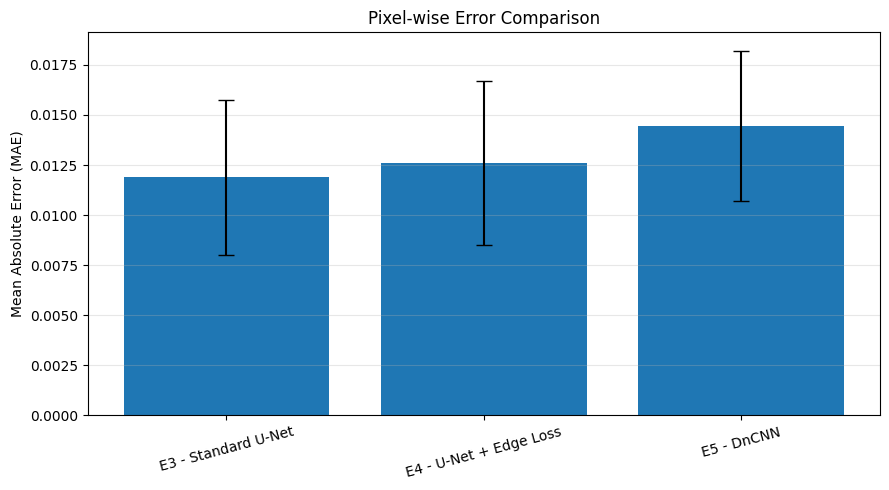

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    error_df["Experiment"],
    error_df["Mean MAE"],
    yerr=error_df["Std MAE"],
    capsize=6
)

plt.ylabel("Mean Absolute Error (MAE)")
plt.title("Pixel-wise Error Comparison")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [24]:
import os

results_dir = "/content/drive/MyDrive/Microscopy-Denoising/results"
os.makedirs(results_dir, exist_ok=True)

# Save MAE results
error_df.to_csv(
    os.path.join(results_dir, "error_analysis.csv"),
    index=False
)

# Save graph
mae_figure_path = os.path.join(results_dir, "mae_comparison.png")

plt.savefig(mae_figure_path, dpi=300, bbox_inches="tight")

print("MAE results saved:", os.path.exists(
    os.path.join(results_dir, "error_analysis.csv")
))

print("MAE graph saved:", os.path.exists(mae_figure_path))

MAE results saved: True
MAE graph saved: True


<Figure size 640x480 with 0 Axes>

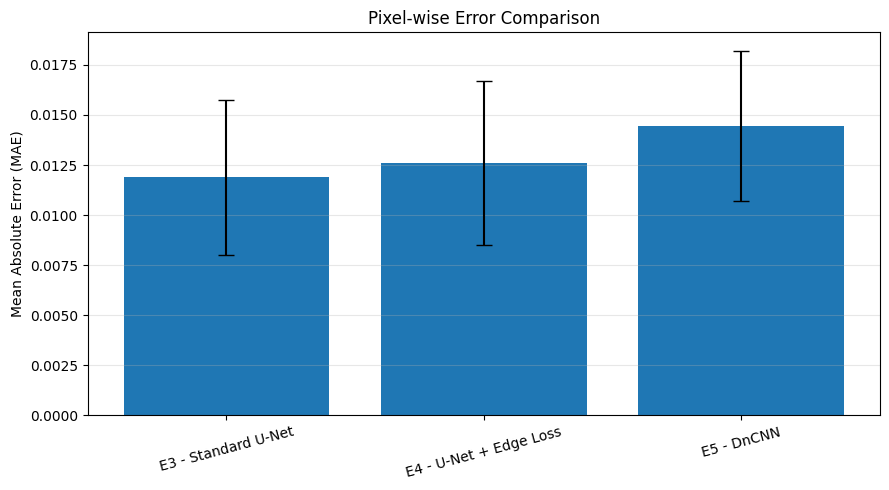

In [25]:
plt.figure(figsize=(9, 5))

plt.bar(
    error_df["Experiment"],
    error_df["Mean MAE"],
    yerr=error_df["Std MAE"],
    capsize=6
)

plt.ylabel("Mean Absolute Error (MAE)")
plt.title("Pixel-wise Error Comparison")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(mae_figure_path, dpi=300, bbox_inches="tight")
plt.show()